# NumPy Hands-on Lab: From Arrays to Image Analysis

## Student Practice Notebook

**Name:** N.Shanmuka Abhiram

**Register Number:**
AP24110011380
  
**Date:** 15-08-2026  

## Learning Objectives

After completing this lab, you will be able to:

- Create and manipulate NumPy arrays
- Understand array properties and dimensions
- Perform indexing and slicing
- Apply mathematical operations
- Understand and explain broadcasting
- Analyze images using NumPy arrays
- Perform basic image transformations
- Explain *why* NumPy is used in real ML/Data Science pipelines, not just *how*

### How to use this notebook
- **Demonstration** cells: run them, read the output, understand it.
- **Practice** cells: write your own code — don't copy the demo verbatim.
- **Predict-then-run**: before running some cells, you'll be asked to *predict* the output first. Write your prediction in the markdown cell, then run and compare.
- **Reflection**: short written answers, in your own words.


## Part 1: Introduction to NumPy

NumPy (Numerical Python) is a Python library used for efficient numerical computation.

**Why not just use Python lists?** Python lists store objects with overhead per element and loop in pure Python. NumPy arrays store raw numbers in contiguous memory and use compiled C code for operations — this is called **vectorization**. That's why NumPy is used everywhere in:

- Data Science (pandas is built on NumPy)
- Machine Learning (feeding data into models as arrays/tensors)
- Image Processing (an image *is* a NumPy array)
- Scientific Computing

Let's actually *see* the speed difference before we take it on faith.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

print("NumPy is ready!")


NumPy is ready!


### Demonstration: Loops vs. Vectorization (the "why" behind NumPy)

Below we add 1 to a million numbers two ways: a plain Python loop, and a NumPy array operation.
Run this cell and look at the timing output.


In [2]:
import time

n = 1_000_000  # Set the number of values to one million
python_list = list(range(n))  # Create a Python list containing numbers from 0 to n-1
numpy_array = np.arange(n)  # Create a NumPy array containing numbers from 0 to n-1

start = time.time()  # Record the start time for the Python loop
result_list = [x + 1 for x in python_list]  # Add 1 to every list element using a Python loop
loop_time = time.time() - start  # Calculate the time taken by the Python loop

start = time.time()  # Record the start time for the NumPy operation
result_array = numpy_array + 1  # Add 1 to every array element using vectorization
vector_time = time.time() - start  # Calculate the time taken by the NumPy operation

print(f"Python loop time : {loop_time:.5f} seconds")
print(f"NumPy vector time: {vector_time:.5f} seconds")
print(f"NumPy was about {loop_time/vector_time:.0f}x faster")


Python loop time : 0.04934 seconds
NumPy vector time: 0.00421 seconds
NumPy was about 12x faster


**Reflection (write your answer):** Based on the timing above, in your own words, why is NumPy faster than a Python loop for this kind of operation?

*Your answer:* NumPy is faster because it can perform operations on many array elements at once using optimized operations, while a Python loop processes each element one by one.


## Part 2: Creating NumPy Arrays

### Demonstration

In [3]:
arr = np.array([10,20,30,40,50])  # Create a NumPy array with five values
arr


array([10, 20, 30, 40, 50])

### Student Practice

Create an array containing:

5, 10, 15, 20, 25

Write your code below (do not just copy the demo — change the numbers yourself):


In [4]:
arr = np.array([5, 10, 15, 20, 25])  # Create an array with the requested values
arr


array([ 5, 10, 15, 20, 25])

## Part 3: Array Properties

Important properties:

- `ndim` : Number of dimensions
- `shape` : Size of each dimension
- `size` : Total number of elements
- `dtype` : Data type

**Predict first:** for the array `arr` from Part 2, what do you *expect* `ndim`, `shape`, `size`, and `dtype` to be? Write your guess below before running the next cell.

*Your prediction:* ndim = 1, shape = (5,), size = 5, dtype = int.


In [5]:
arr.ndim, arr.shape, arr.size, arr.dtype  # Display dimensions, shape, element count, and data type


(1, (5,), 5, dtype('int64'))

### Observation

Was your prediction correct? yes my prediction is correct

Dimension: 1

Shape: (5,)

Size: 5

Data Type: int64


## Part 4: Special Arrays

These are commonly used to initialize data — for example, `zeros` is often used to create an empty "canvas" array before filling in real values (you'll see this again in the image section).


In [6]:
np.zeros((3,3))  # Create a 3x3 array filled with zeros


array([[0., 0., 0.],
       [0., 0., 0.],
       [0., 0., 0.]])

In [7]:
np.ones((4,4))  # Create a 4x4 array filled with ones


array([[1., 1., 1., 1.],
       [1., 1., 1., 1.],
       [1., 1., 1., 1.],
       [1., 1., 1., 1.]])

In [8]:
np.eye(3)  # Create a 3x3 identity matrix with ones on the diagonal


array([[1., 0., 0.],
       [0., 1., 0.],
       [0., 0., 1.]])

### Student Practice

Create a `5x5` array of all zeros, and a `2x6` array of all ones. Write both below.


In [9]:
zeros_array = np.zeros((5, 5))  # Create a 5x5 array of zeros
ones_array = np.ones((2, 6))  # Create a 2x6 array of ones

print(zeros_array)
print(ones_array)


[[0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]]
[[1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1.]]


## Part 5: Sequence Generation

In [10]:
np.arange(0,50,5)  # Generate numbers from 0 to 45 with a step of 5


array([ 0,  5, 10, 15, 20, 25, 30, 35, 40, 45])

In [11]:
np.linspace(0,100,10)  # Generate 10 evenly spaced values from 0 to 100


array([  0.        ,  11.11111111,  22.22222222,  33.33333333,
        44.44444444,  55.55555556,  66.66666667,  77.77777778,
        88.88888889, 100.        ])

### Student Practice

`np.arange` and `np.linspace` both generate sequences but work differently.

1. Use `np.arange` to generate even numbers from 2 to 20.
2. Use `np.linspace` to generate 5 evenly spaced numbers between 0 and 1.
3. In one sentence, write the difference between `arange` (step-based) and `linspace` (count-based).


In [12]:
even_numbers = np.arange(2, 21, 2)  # Generate even numbers from 2 through 20
spaced_numbers = np.linspace(0, 1, 5)  # Generate 5 evenly spaced values between 0 and 1

print(even_numbers)
print(spaced_numbers)
print("arange is step-based, while linspace is count-based.")


[ 2  4  6  8 10 12 14 16 18 20]
[0.   0.25 0.5  0.75 1.  ]
arange is step-based, while linspace is count-based.


## Part 6: Random Numbers

In [13]:
np.random.rand(5)  # Generate five random floating-point values between 0 and 1


array([0.96041158, 0.047579  , 0.50959996, 0.3579348 , 0.77424681])

In [14]:
np.random.randint(1,100,10)  # Generate 10 random integers from 1 up to 99


array([95, 35, 39, 36, 99, 55, 43, 55, 18, 88])

## Part 7: Reshaping Arrays

Reshape changes the *structure* of an array without changing the data.

**Rule: the total number of elements must stay the same.** `3x4 = 12` elements, so you can reshape into any combination of dimensions that multiplies to 12 (e.g. `2x6`, `4x3`, `1x12`, `12x1`).


In [15]:
a = np.arange(12)  # Create an array containing 12 values from 0 to 11
a.reshape(3,4)  # Reshape the 12 values into 3 rows and 4 columns


array([[ 0,  1,  2,  3],
       [ 4,  5,  6,  7],
       [ 8,  9, 10, 11]])

### Student Practice — valid shapes

Try reshaping `a` into these shapes. Write each as a separate line:
- 2 x 6
- 4 x 3
- 6 x 2


In [16]:
a.reshape(2, 6)  # Reshape the array into 2 rows and 6 columns
a.reshape(4, 3)  # Reshape the array into 4 rows and 3 columns
a.reshape(6, 2)  # Reshape the array into 6 rows and 2 columns


array([[ 0,  1],
       [ 2,  3],
       [ 4,  5],
       [ 6,  7],
       [ 8,  9],
       [10, 11]])

### Student Practice — break it on purpose

Now try `a.reshape(5,3)`. This should throw an error because 5 × 3 = 15 ≠ 12.

Run it, read the error message, then answer: **why did it fail, and what rule does it confirm about reshape?**

*Your answer:* It failed because the original array has 12 elements, but a 5 × 3 array requires 15 elements. The reshape operation must keep the total number of elements unchanged. Therefore, the new shape must have dimensions whose product is equal to the original array size.


In [17]:
a.reshape(5, 3)  # This intentionally raises an error because 5x3 does not contain 12 elements


ValueError: cannot reshape array of size 12 into shape (5,3)

## Part 8: Indexing and Slicing

In [18]:
matrix = np.arange(1,10).reshape(3,3)  # Create a 3x3 matrix containing values 1 to 9
matrix


array([[1, 2, 3],
       [4, 5, 6],
       [7, 8, 9]])

In [19]:
# Extract first row
matrix[0]  # Select row index 0, which is the first row


array([1, 2, 3])

In [20]:
# Extract first column
matrix[:,0]  # Select all rows from column index 0, the first column


array([1, 4, 7])

### Student Practice

Using `matrix` above, write code to extract:
1. The last row
2. The last column
3. The single element in the middle (row 1, column 1)
4. The bottom-right 2x2 sub-matrix


In [21]:
matrix[-1]  # Extract the last row
matrix[:, -1]  # Extract the last column
matrix[1, 1]  # Extract the middle element at row 1, column 1
matrix[1:, 1:]  # Extract the bottom-right 2x2 sub-matrix


array([[5, 6],
       [8, 9]])

## Part 9: Mathematical Operations

In [22]:
marks = np.array([60,70,80,90])  # Create an array containing four marks

marks + 5  # Add 5 to every mark using NumPy broadcasting


array([65, 75, 85, 95])

In [23]:
marks * 2  # Multiply every mark by 2 using element-wise multiplication


array([120, 140, 160, 180])

### Student Practice

A student scored `marks = [55, 62, 48, 91, 73]` but every question was later found to be worth 1 extra bonus mark, and then the whole test was scaled to be out of 150 (currently out of 100, so multiply by 1.5).

Write the NumPy code to: (1) add the bonus mark to every score, then (2) scale to out of 150.


In [24]:
marks = np.array([55, 62, 48, 91, 73])  # Create the student's original marks
bonus_marks = marks + 1  # Add one bonus mark to every score
scaled_marks = bonus_marks * 1.5  # Scale the updated scores from 100 to 150

print("After bonus:", bonus_marks)
print("Scaled to 150:", scaled_marks)


After bonus: [56 63 49 92 74]
Scaled to 150: [ 84.   94.5  73.5 138.  111. ]


## Part 10: Broadcasting

Broadcasting lets NumPy perform operations between arrays of **different shapes**, without writing an explicit loop, by "stretching" the smaller array to match the larger one — as long as their shapes are compatible.

**The basic rule:** starting from the trailing (rightmost) dimension, two dimensions are compatible if they're equal, or one of them is 1. NumPy then virtually repeats the size-1 dimension to match.

You already used broadcasting in Part 9 (`marks + 5`) — a single number (shape `()`) was broadcast across the whole array. Here's a less obvious example: a 1D array broadcast across a 2D array.


In [25]:
salary = np.array([30000,40000,50000])  # Create an array containing three salaries

salary * 1.10  # Increase every salary by 10 percent using broadcasting


array([33000., 44000., 55000.])

In [26]:
# A less obvious broadcasting example: adding a 1D array to every row of a 2D array
grid = np.ones((3,3))  # Create a 3x3 array of ones; its shape is (3,3)
row_bonus = np.array([1,2,3])  # Create a 1D array of three bonus values; its shape is (3,)

grid + row_bonus  # Add the row bonus to every row through broadcasting


array([[2., 3., 4.],
       [2., 3., 4.],
       [2., 3., 4.]])

### Student Practice — predict then check

Before running the next cell, predict the output shape and values on paper.

`np.array([[1],[2],[3]]) + np.array([10,20,30])`

(Hint: one array has shape `(3,1)`, the other `(3,)`. Think about how each dimension aligns.)

*Your prediction:* Output shape: (3, 3)

Output:
[[11, 21, 31],
 [12, 22, 32],
 [13, 23, 33]]


In [27]:
# Run this after writing your prediction above, and compare
np.array([[1],[2],[3]]) + np.array([10,20,30])  # Broadcast the (3,) array across the (3,1) array


array([[11, 21, 31],
       [12, 22, 32],
       [13, 23, 33]])

**Reflection:** In your own words, explain broadcasting with an example of your own (not one from this notebook).

*Your answer:*

Broadcasting allows NumPy to perform operations between arrays of different but compatible shapes by automatically adjusting them.

For example, if a = np.array([10, 20, 30]) and b = np.array([[1], [2]]), adding them produces:
[[11, 21, 31],
 [12, 22, 32]]

Here, NumPy automatically broadcasts the two arrays to compatible shapes before performing the addition.


## Part 11: Filtering Data (Boolean Indexing)

In [28]:
marks = np.array([45,67,89,32,90,55])  # Create an array containing student marks

marks[marks > 60]  # Select only marks greater than 60 using a Boolean mask


array([67, 89, 90])

### Student Practice

Using the `marks` array above:
1. Extract all marks that are failing (below 40).
2. Count how many students scored above 80 (hint: `.sum()` on a boolean array counts `True` values).
3. Replace all failing marks with 0 using `np.where`.


In [29]:
failing_marks = marks[marks < 40]  # Extract all marks below 40
above_80_count = (marks > 80).sum()  # Count the number of marks above 80
marks_replaced = np.where(marks < 40, 0, marks)  # Replace every failing mark with 0

print("Failing marks:", failing_marks)
print("Students above 80:", above_80_count)
print("Marks after replacement:", marks_replaced)


Failing marks: [32]
Students above 80: 2
Marks after replacement: [45 67 89  0 90 55]


## Part 12: Joining Arrays

In [30]:
a=np.array([1,2,3])  # Create the first NumPy array
b=np.array([4,5,6])  # Create the second NumPy array

np.concatenate([a,b])  # Join the two arrays into one array


array([1, 2, 3, 4, 5, 6])

## Part 13: Splitting Arrays

In [31]:
x=np.arange(12)  # Create an array containing 12 values from 0 to 11

np.split(x,3)  # Split the array into three equal parts


[array([0, 1, 2, 3]), array([4, 5, 6, 7]), array([ 8,  9, 10, 11])]

### Student Practice

1. Split `x` into 4 equal parts instead of 3.
2. Try `np.split(x, 5)` — this should fail. Read the error and explain in one sentence why splitting into 5 doesn't work for 12 elements.


In [32]:
np.split(x, 4)  # Split 12 elements into four equal parts
np.split(x, 5)  # Intentionally raises an error because 12 cannot be split into 5 equal parts


ValueError: array split does not result in an equal division

# Part 14: Image Analysis Using NumPy

## Why this matters for ML

A digital image **is** a NumPy array — this is exactly the data format used to feed images into computer vision models (e.g. CNNs). Every preprocessing step you do below (resizing, cropping, normalizing pixel values, flipping for data augmentation) is a real step used in production ML image pipelines, not just a classroom exercise.

## Image Shape Guidelines

A colour image is represented as:

`(height, width, channels)`

Example: `512 x 512 x 3` means:
- Height = 512 pixels
- Width = 512 pixels
- RGB colour channels = 3

**Avoid very large images** — a `4000 x 4000 x 3` image has 48 million individual pixel values. That's a lot to process and display.

Recommended:
- Practice: 300x300 pixels
- Processing: 512x512 pixels


In [34]:
from google.colab import files

uploaded = files.upload()  # Open the upload dialog and store uploaded files


Saving Image for notebook.avif to Image for notebook.avif


In [35]:
# The 'uploaded' variable is a dictionary: {filename: file_bytes}
# This line grabs the filename automatically instead of you typing it by hand
image_filename = list(uploaded.keys())[0]  # Get the first uploaded filename
print("Uploaded file:", image_filename)


Uploaded file: Image for notebook.avif


> **Note:** the cell above only works in Google Colab. If you're running this notebook locally (Jupyter/VS Code), skip it and instead set `image_path = "your_local_file.jpg"` directly in the next cell.

Upload an image file and note its name below:

Image name:


In [36]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt


img_array = np.array(Image.open(image_filename))  # Open the image and convert it to a NumPy array
print("Image shape:", img_array.shape)


Image shape: (900, 1600, 3)


## Image Display

**Do not print the complete image array** (it's thousands of numbers and unreadable). Instead:
- Use `image.shape` to check dimensions
- Use `plt.imshow(...)` to *see* the image visually

### Student Practice
Display your uploaded image using `plt.imshow()` and turn off the axis with `plt.axis("off")`.


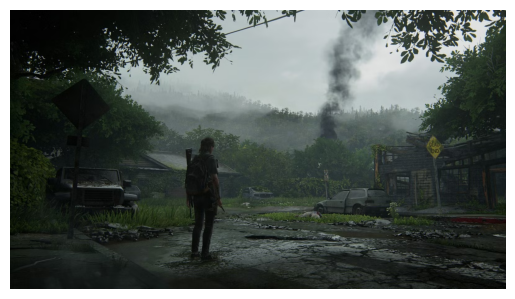

In [37]:
plt.imshow(img_array)  # Display the image
plt.axis("off")
plt.show()


## Image Cropping

### Student Practice
Crop the **center 200x200 region** of your image (not a random corner — think about how to calculate the center offset from `img_array.shape`), store it in a variable called `crop`, and display it.


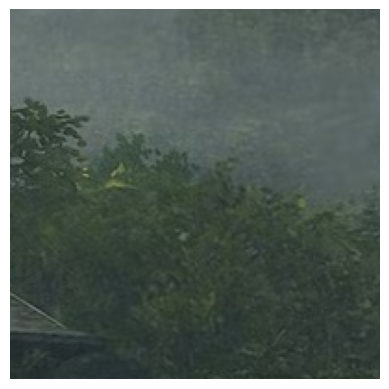

In [38]:
height, width = img_array.shape[:2]  # Get the image height and width
start_y = (height - 200) // 2  # Calculate the starting row for the centered crop
start_x = (width - 200) // 2  # Calculate the starting column for the centered crop
crop = img_array[start_y:start_y + 200, start_x:start_x + 200]  # Extract the center 200x200 region

plt.imshow(crop)  # Display the cropped region
plt.axis("off")
plt.show()


### Quick demo: showing multiple images side by side

You'll want to display more than one image at once in the tasks below (e.g. two flipped versions, or three RGB channels). `plt.subplots()` lets you do this in a grid. Study this small example, then reuse the pattern.


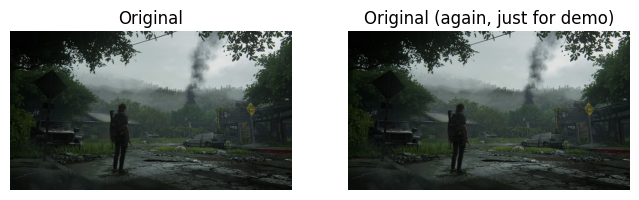

In [39]:
# Demo: showing 2 plots side by side using plt.subplots
fig, axes = plt.subplots(1, 2, figsize=(8,4))  # Create a figure with two side-by-side plotting areas

axes[0].imshow(img_array)  # Display the image in the first plotting area
axes[0].set_title("Original")
axes[0].axis("off")

axes[1].imshow(img_array)
axes[1].set_title("Original (again, just for demo)")
axes[1].axis("off")

plt.show()


## Image Flipping

### Student Practice
Produce and display both a vertical flip and a horizontal flip of your image using slicing (`[::-1]`), without using any built-in flip function.


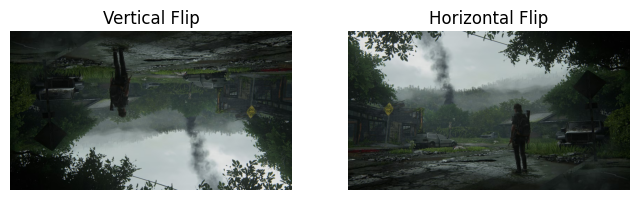

In [40]:
vertical_flip = img_array[::-1, :]  # Flip the image vertically by reversing the row order
horizontal_flip = img_array[:, ::-1]  # Flip the image horizontally by reversing the column order

fig, axes = plt.subplots(1, 2, figsize=(8, 4))  # Create two side-by-side plots
axes[0].imshow(vertical_flip)  # Display the vertical flip
axes[0].set_title("Vertical Flip")
axes[0].axis("off")
axes[1].imshow(horizontal_flip)
axes[1].set_title("Horizontal Flip")
axes[1].axis("off")
plt.show()


## RGB Channel Analysis

RGB channels:

- 0 - Red
- 1 - Green
- 2 - Blue

### Student Practice
Extract the red, green, and blue channels separately, and display each one using `plt.imshow(channel, cmap="gray")` so you can see which areas of the image are strongest in each color.


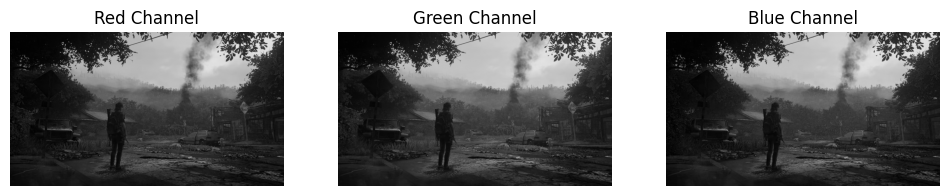

In [41]:
red_channel = img_array[:, :, 0]  # Extract the red channel
green_channel = img_array[:, :, 1]
blue_channel = img_array[:, :, 2]

fig, axes = plt.subplots(1, 3, figsize=(12, 4))  # Create three side-by-side plots
axes[0].imshow(red_channel, cmap="gray")  # Display the red channel in grayscale
axes[0].set_title("Red Channel")
axes[0].axis("off")
axes[1].imshow(green_channel, cmap="gray")
axes[1].set_title("Green Channel")
axes[1].axis("off")
axes[2].imshow(blue_channel, cmap="gray")
axes[2].set_title("Blue Channel")
axes[2].axis("off")
plt.show()


## Brightness Analysis

### Student Practice
Calculate the average brightness of your image using `np.mean()`. Then calculate the average brightness of just the red channel, just the green channel, and just the blue channel. Which channel is brightest? Write your answer below the code.


In [42]:
overall_brightness = np.mean(img_array)  # Calculate the average value across all pixels and channels
red_brightness = np.mean(img_array[:, :, 0])  # Calculate the average brightness of the red channel
green_brightness = np.mean(img_array[:, :, 1])
blue_brightness = np.mean(img_array[:, :, 2])

print("Overall brightness:", overall_brightness)
print("Red brightness:", red_brightness)
print("Green brightness:", green_brightness)
print("Blue brightness:", blue_brightness)

brightest_channel = max(
    [("Red", red_brightness), ("Green", green_brightness), ("Blue", blue_brightness)],
    key=lambda item: item[1]
)[0]  # Find the channel with the highest average brightness
print("Brightest channel:", brightest_channel)


Overall brightness: 68.92412800925926
Red brightness: 64.92733958333334
Green brightness: 73.16086875
Blue brightness: 68.68417569444445
Brightest channel: Green


*Your answer:* The green channel is the brightest because it has the highest average brightness value (73.16).


## Thresholding

Convert the image into pure black-and-white using `np.where()`.

### Student Practice
1. Convert the image to grayscale by averaging the 3 channels (`axis=2`).
2. Use `np.where(gray > 128, 255, 0)` to create a binary (black/white) version.
3. Display the result.
4. Try a different threshold (e.g. 100 or 180) and observe how it changes the result.


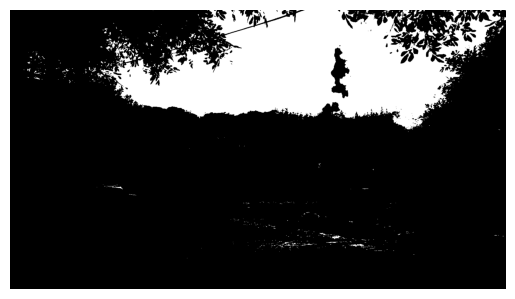

In [43]:
gray = np.mean(img_array[:, :, :3], axis=2)  # Convert the RGB image to grayscale by averaging the channels
binary = np.where(gray > 128, 255, 0)  # Create a black-and-white image using threshold 128

plt.imshow(binary, cmap="gray")  # Display the thresholded image in grayscale
plt.axis("off")
plt.show()

binary_100 = np.where(gray > 100, 255, 0)  # Create another binary image using threshold 100
binary_180 = np.where(gray > 180, 255, 0)


# Mini Project: Image Analyzer

Write a single program (you can reuse code from above) that prints/displays all of the following for your uploaded image, in order:

1. Image height, width, and number of channels
2. Average brightness (overall, and per channel)
3. The cropped center region
4. Both flipped versions (vertical and horizontal)
5. All 3 RGB channels shown separately
6. The thresholded (black/white) version

Answer: Written in a new code cell below

### Self-check before you submit
- [x] I wrote the code myself rather than only uncommenting given code
- [x] I can explain what every line does, not just that it runs
- [x] My image display uses `plt.axis("off")` and looks correct
- [x] I answered all reflection questions in my own words

## Reflection Questions

1. Why is NumPy faster than Python lists? (Refer back to your Part 1 answer — refine it if needed.)

Ans: NumPy is faster because it stores data efficiently in arrays and performs operations using optimized code. It can perform operations on many elements at the same time instead of processing each element individually using Python loops.


2. Explain broadcasting with an example of your own.

Ans: Broadcasting allows NumPy to perform operations between arrays of compatible shapes without manually changing their sizes.

Example:

a = np.array([10, 20, 30])
b = 5

print(a + b)

Output:
[15 25 35]

Here the value 5 is automatically added to every element of the array.


3. What does image shape `(512,512,3)` represent?

Ans: The shape (512,512,3) represents an image with 512 pixels in height, 512 pixels in width, and 3 color channels. The three channels are Red, Green, and Blue (RGB).

4. Why should we avoid printing complete image arrays?

Ans: We should avoid printing complete image arrays because an image contains a large number of pixel values. Printing all the values makes the output very large and difficult to read. Instead, we can display the image or check its properties such as shape and data type.

5. Explain RGB channels.

Ans: RGB stands for Red, Green, and Blue. A color image contains three separate channels, one for each color. Each pixel has a value for red, green, and blue, and these values combine to produce the final color of the pixel.

6. Where might you use this exact image-array workflow in a real machine learning project (e.g. what comes right before feeding an image into a CNN)?

Ans: This workflow can be used during image preprocessing before feeding an image into a CNN (Convolutional Neural Network). The image can be loaded as an array, resized or cropped, converted into the required format, and normalized before being passed to the machine learning model for tasks such as image classification.



Height: 900
Width: 1600
Channels: 3
Overall brightness: 68.92412800925926
Red brightness: 64.92733958333334
Green brightness: 73.16086875
Blue brightness: 68.68417569444445


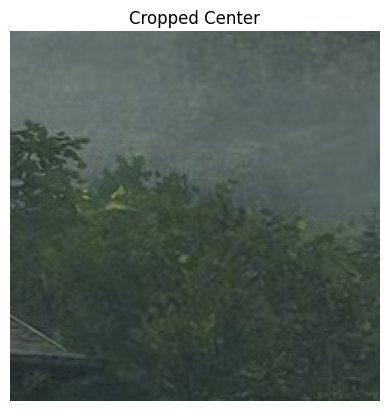

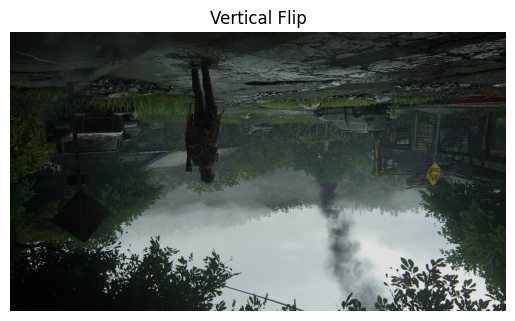

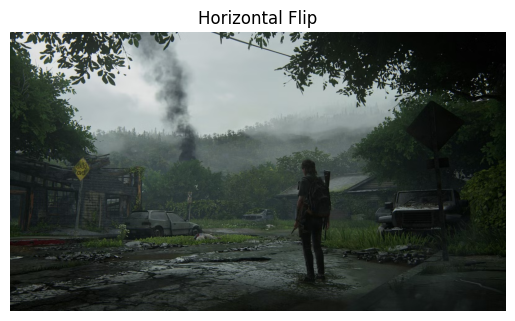

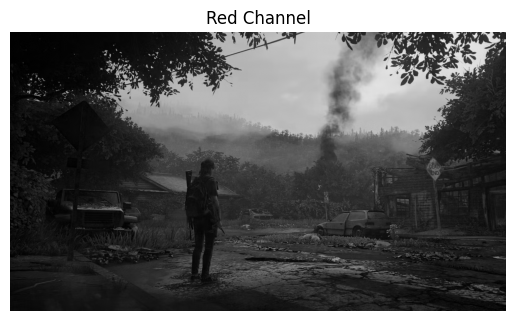

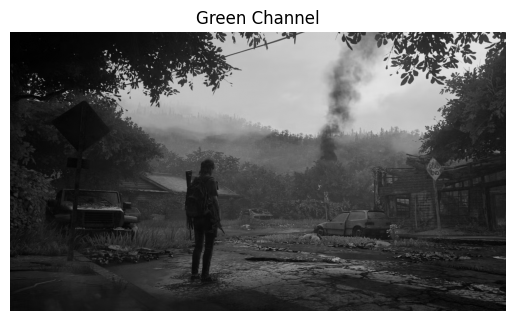

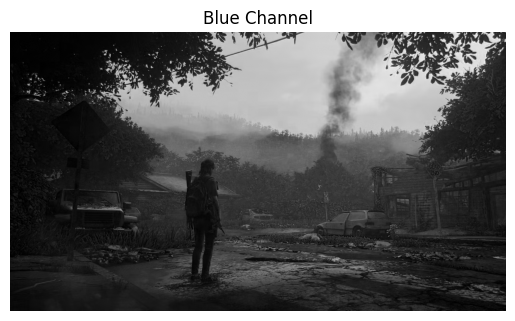

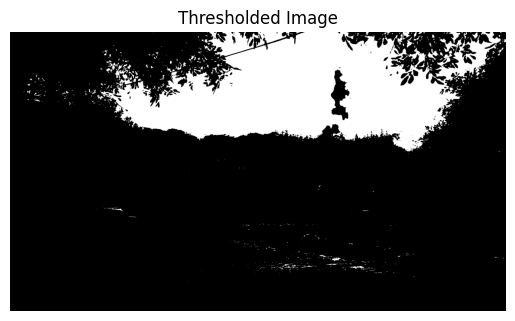

In [53]:
# 1. Image height, width, and number of channels
height, width = img_array.shape[:2]
channels = img_array.shape[2] if img_array.ndim == 3 else 1

print("Height:", height)
print("Width:", width)
print("Channels:", channels)

# 2. Average brightness
print("Overall brightness:", np.mean(img_array))

if channels >= 3:
    print("Red brightness:", np.mean(img_array[:, :, 0]))
    print("Green brightness:", np.mean(img_array[:, :, 1]))
    print("Blue brightness:", np.mean(img_array[:, :, 2]))

# 3. Cropped center region
start_y = (height - 200) // 2
start_x = (width - 200) // 2
crop = img_array[start_y:start_y+200, start_x:start_x+200]

plt.imshow(crop)
plt.title("Cropped Center")
plt.axis("off")
plt.show()

# 4. Vertical and horizontal flips
vertical_flip = img_array[::-1, :]
horizontal_flip = img_array[:, ::-1]

plt.imshow(vertical_flip)
plt.title("Vertical Flip")
plt.axis("off")
plt.show()

plt.imshow(horizontal_flip)
plt.title("Horizontal Flip")
plt.axis("off")
plt.show()

# 5. RGB channels
plt.imshow(img_array[:, :, 0], cmap="gray")
plt.title("Red Channel")
plt.axis("off")
plt.show()

plt.imshow(img_array[:, :, 1], cmap="gray")
plt.title("Green Channel")
plt.axis("off")
plt.show()

plt.imshow(img_array[:, :, 2], cmap="gray")
plt.title("Blue Channel")
plt.axis("off")
plt.show()

# 6. Thresholded black/white version
gray = np.mean(img_array[:, :, :3], axis=2)
binary = np.where(gray > 128, 255, 0)

plt.imshow(binary, cmap="gray")
plt.title("Thresholded Image")
plt.axis("off")
plt.show()

# Part 15: Text Analysis Using NumPy (NLP Track)

## Why this matters for ML/NLP

Before any NLP model (sentiment classifier, spam detector, chatbot) can process text, the text must be converted into numbers — this is called **vectorization**. NumPy arrays are the underlying data structure for almost every text representation: word counts, one-hot vectors, TF-IDF vectors, and even word embeddings are all just NumPy (or NumPy-like) arrays.

In this section, you'll build a small text analysis pipeline entirely with NumPy — no external NLP libraries — so you understand what's actually happening under the hood before you use libraries like `scikit-learn` or `nltk` later in the course.


## Step 1: From Text to Tokens

The first step in any NLP pipeline is **tokenization** — splitting text into individual words.

### Demonstration


In [44]:
sentence = "NumPy makes numerical computing fast and NumPy makes arrays powerful"  # Store the sample sentence

# Basic tokenization: lowercase + split on spaces
tokens = sentence.lower().split()  # Convert the sentence to lowercase and split it into words
print(tokens)


['numpy', 'makes', 'numerical', 'computing', 'fast', 'and', 'numpy', 'makes', 'arrays', 'powerful']


### Student Practice

Tokenize this sentence the same way: `"Data Science and Machine Learning use NumPy arrays every single day"`. Store the result in a variable called `tokens2`.


In [45]:
sentence2 = "Data Science and Machine Learning use NumPy arrays every single day"  # Store the practice sentence
tokens2 = sentence2.lower().split()  # Convert to lowercase and split into individual words
print(tokens2)


['data', 'science', 'and', 'machine', 'learning', 'use', 'numpy', 'arrays', 'every', 'single', 'day']


## Step 2: Building a Vocabulary

A **vocabulary** is the set of all unique words across your text(s). We'll use `np.unique()` — the same function idea you used earlier for arrays of numbers, now applied to an array of words.


In [46]:
tokens_array = np.array(tokens)  # Convert the list of tokens into a NumPy array
vocabulary = np.unique(tokens_array)  # Find the unique words and sort them
print("Vocabulary:", vocabulary)
print("Vocabulary size:", len(vocabulary))


Vocabulary: ['and' 'arrays' 'computing' 'fast' 'makes' 'numerical' 'numpy' 'powerful']
Vocabulary size: 8


### Student Practice

Build the vocabulary for `tokens2` from Step 1. How many unique words does it contain?


In [47]:
tokens2_array = np.array(tokens2)  # Convert tokens2 into a NumPy array
vocabulary2 = np.unique(tokens2_array)  # Find the unique words in tokens2
print("Vocabulary:", vocabulary2)
print("Vocabulary size:", len(vocabulary2))


Vocabulary: ['and' 'arrays' 'data' 'day' 'every' 'learning' 'machine' 'numpy'
 'science' 'single' 'use']
Vocabulary size: 11


## Step 3: Word Frequency Vector (Bag-of-Words)

A **bag-of-words** vector represents a sentence as an array of word counts, one count per vocabulary word — this ignores word order but captures *what* words appear and *how often*.

### Demonstration: build a word-count vector by hand using NumPy


In [48]:
def bag_of_words_vector(tokens, vocabulary):  # Define a function that creates a word-count vector
    # For each word in the vocabulary, count how many times it appears in tokens
    vector = np.array([np.sum(np.array(tokens) == word) for word in vocabulary])  # Count each vocabulary word
    return vector  # Return the resulting count vector

vec = bag_of_words_vector(tokens, vocabulary)
print(vocabulary)
print(vec)


['and' 'arrays' 'computing' 'fast' 'makes' 'numerical' 'numpy' 'powerful']
[1 1 1 1 2 1 2 1]


### Student Practice — predict then check

Before running, predict: which word(s) will have a count of 2 in the vector above? (Hint: look back at the original sentence — which word repeats?)

*Your prediction:* The words makes and numpy will have a count of 2.

Now build the bag-of-words vector for `tokens2` using its own vocabulary, and check your prediction concept applies the same way.


In [49]:
vec2 = bag_of_words_vector(tokens2, vocabulary2)  # Build a bag-of-words vector for tokens2
print("Vocabulary:", vocabulary2)
print("Bag-of-words vector:", vec2)


Vocabulary: ['and' 'arrays' 'data' 'day' 'every' 'learning' 'machine' 'numpy'
 'science' 'single' 'use']
Bag-of-words vector: [1 1 1 1 1 1 1 1 1 1 1]


## Step 4: Comparing Two Sentences (Cosine Similarity)

Once text is turned into number vectors, we can measure how *similar* two sentences are using **cosine similarity** — a formula you'll see constantly in NLP and recommendation systems:

$$\text{cosine similarity} = \frac{A \cdot B}{\|A\| \times \|B\|}$$

This measures the angle between two vectors, not their length — so it works even if one sentence is longer than another.

### Demonstration


In [50]:
sentence_a = "machine learning uses numpy arrays"  # Store the first sample sentence
sentence_b = "deep learning also uses numpy arrays heavily"  # Store the second sample sentence

tokens_a = sentence_a.lower().split()  # Tokenize the first sentence
tokens_b = sentence_b.lower().split()  # Tokenize the second sentence

# Build a shared vocabulary from both sentences combined
combined_vocab = np.unique(np.array(tokens_a + tokens_b))  # Create one vocabulary for both sentences

vec_a = bag_of_words_vector(tokens_a, combined_vocab)  # Convert sentence A into a count vector
vec_b = bag_of_words_vector(tokens_b, combined_vocab)  # Convert sentence B into a count vector

print("Vector A:", vec_a)
print("Vector B:", vec_b)

# Cosine similarity using NumPy dot product and norm
cosine_sim = np.dot(vec_a, vec_b) / (np.linalg.norm(vec_a) * np.linalg.norm(vec_b))  # Calculate cosine similarity
print("Cosine similarity:", cosine_sim)


Vector A: [0 1 0 0 1 1 1 1]
Vector B: [1 1 1 1 1 0 1 1]
Cosine similarity: 0.6761234037828131


### Student Practice

Pick two sentences of your own (write them below) — one pair that should be *similar* in meaning/topic, and one pair that should be *very different*. Compute the cosine similarity for both pairs and confirm your intuition matches the numbers.


In [51]:
similar_a = "machine learning is useful for data analysis"  # Similar-pair sentence 1
similar_b = "data analysis is useful with machine learning"  # Similar-pair sentence 2
different_a = "machine learning is useful for data analysis"  # Different-pair sentence 1
different_b = "the garden has colorful flowers and green trees"  # Different-pair sentence 2

def cosine_similarity(sentence1, sentence2):  # Define a helper function for cosine similarity
    tokens1 = sentence1.lower().split()  # Tokenize the first sentence
    tokens2_local = sentence2.lower().split()  # Tokenize the second sentence
    vocab = np.unique(np.array(tokens1 + tokens2_local))  # Build a shared vocabulary
    vector1 = bag_of_words_vector(tokens1, vocab)
    vector2 = bag_of_words_vector(tokens2_local, vocab)
    return np.dot(vector1, vector2) / (np.linalg.norm(vector1) * np.linalg.norm(vector2))  # Calculate cosine similarity

similar_score = cosine_similarity(similar_a, similar_b)  # Calculate similarity for the similar pair
different_score = cosine_similarity(different_a, different_b)  # Calculate similarity for the different pair

print("Similar pair cosine similarity:", similar_score)
print("Different pair cosine similarity:", different_score)


Similar pair cosine similarity: 0.857142857142857
Different pair cosine similarity: 0.0


**Reflection:** In your own words, why does cosine similarity give a value close to 1 for similar sentences and close to 0 for unrelated sentences? What would a `cosine similarity` of exactly 1 mean about two vectors?

*Your answer:*

 Cosine similarity is close to 1 when two sentences have similar words and meaning because their vectors point in similar directions. For unrelated sentences, it is close to 0 because their vectors are different. A cosine similarity of exactly 1 means the two vectors point in exactly the same direction.


## Step 5: Most Frequent Words

### Student Practice

Take any paragraph of your choice (3-4 sentences, write it below as a string). Then:
1. Tokenize it.
2. Build its vocabulary and word-count vector (reuse `bag_of_words_vector`).
3. Use NumPy to find and print the **top 3 most frequent words** (hint: look at sorting — `np.argsort()` sorts indices by value, and slicing with `[::-1]` reverses order).


In [52]:
paragraph = "NumPy is useful for numerical computing. NumPy arrays make data processing efficient. Data analysis often uses arrays for calculations. Efficient numerical operations are important in machine learning."  # Store a 4-sentence paragraph
tokens_paragraph = paragraph.lower().split()  # Tokenize the paragraph
vocab_paragraph = np.unique(np.array(tokens_paragraph))  # Build the vocabulary
counts_paragraph = bag_of_words_vector(tokens_paragraph, vocab_paragraph)  # Count each vocabulary word

top_indices = np.argsort(counts_paragraph)[::-1][:3]  # Get indices of the three highest word counts
top_words = vocab_paragraph[top_indices]  # Get the corresponding words
top_counts = counts_paragraph[top_indices]  # Get their frequencies

for word, count in zip(top_words, top_counts):  # Loop through the top three words
    print(word, ":", count)


numpy : 2
numerical : 2
data : 2


# Mini Project: Simple Text Similarity Checker (NLP Track)

Build a small program that:

1. Takes **three** short sentences of your choice (write them as strings).
2. Tokenizes all three and builds one shared vocabulary across all of them.
3. Converts each sentence into a bag-of-words vector using that shared vocabulary.
4. Computes cosine similarity between every pair of sentences (3 pairs total: 1-2, 1-3, 2-3).
5. Prints which two sentences are the **most similar** to each other, based on the highest cosine similarity score.

Answer: Written in a new code cell below

### Self-check before you submit
- [x] I wrote my own three sentences (not copied from the notebook)
- [x] I can explain what a bag-of-words vector represents, in my own words
- [x] I can explain why cosine similarity works even when sentences are different lengths
- [x] My program correctly identifies and prints the most similar pair

## Reflection Questions (NLP Track)

1. Why do we need to convert text into numbers before a machine learning model can use it?

Ans: Machine learning models work with numerical data, not directly with words. Therefore, text must be converted into numbers so that the model can perform mathematical calculations and find patterns in the data.

2. What information does a bag-of-words vector *lose* about the original sentence? (Hint: think about what `split()` and counting alone doesn't capture.)

Ans: A bag-of-words vector loses the word order and the context of the sentence. It only records which words are present and how many times each word occurs.


3. Why might cosine similarity be a better similarity measure than simply comparing raw word-count differences?

Ans: Cosine similarity compares the direction of two vectors rather than their size. This makes it useful for comparing sentences of different lengths because the result focuses on their word patterns.


4. Name one real-world application that likely uses something like this text-vectorization + similarity approach (e.g. search engines, plagiarism checkers, recommendation systems — pick one and explain briefly).

Ans: Search engines can use text vectorization and similarity to compare a user's search query with documents. This helps the search engine find and rank results that are more relevant to the user's query.


In [54]:
# Mini Project: Simple Text Similarity Checker (NLP Track)
import numpy as np

# 1. Three original sentences
sentence1 = "Students practice coding in the computer lab"
sentence2 = "Students practice programming in the computer lab"
sentence3 = "The weather is pleasant today"

# 2. Tokenize all three sentences
tokens1 = sentence1.lower().split()
tokens2 = sentence2.lower().split()
tokens3 = sentence3.lower().split()

# Build one shared vocabulary
vocabulary = np.unique(np.array(tokens1 + tokens2 + tokens3))

print("Shared Vocabulary:")
print(vocabulary)

# 3. Convert each sentence into a bag-of-words vector
vec1 = np.array([np.sum(np.array(tokens1) == word) for word in vocabulary])
vec2 = np.array([np.sum(np.array(tokens2) == word) for word in vocabulary])
vec3 = np.array([np.sum(np.array(tokens3) == word) for word in vocabulary])

print("\nBag-of-Words Vectors:")
print("Sentence 1:", vec1)
print("Sentence 2:", vec2)
print("Sentence 3:", vec3)

# 4. Function to calculate cosine similarity
def cosine_similarity(v1, v2):
    return np.dot(v1, v2) / (np.linalg.norm(v1) * np.linalg.norm(v2))

# Calculate similarity for all three pairs
similarity_12 = cosine_similarity(vec1, vec2)
similarity_13 = cosine_similarity(vec1, vec3)
similarity_23 = cosine_similarity(vec2, vec3)

print("\nCosine Similarities:")
print("Sentence 1 and Sentence 2:", similarity_12)
print("Sentence 1 and Sentence 3:", similarity_13)
print("Sentence 2 and Sentence 3:", similarity_23)

# 5. Find the most similar pair
similarities = {
    "Sentence 1 and Sentence 2": similarity_12,
    "Sentence 1 and Sentence 3": similarity_13,
    "Sentence 2 and Sentence 3": similarity_23
}

most_similar = max(similarities, key=similarities.get)

print("\nMost similar pair:", most_similar)
print("Highest cosine similarity:", similarities[most_similar])

Shared Vocabulary:
['coding' 'computer' 'in' 'is' 'lab' 'pleasant' 'practice' 'programming'
 'students' 'the' 'today' 'weather']

Bag-of-Words Vectors:
Sentence 1: [1 1 1 0 1 0 1 0 1 1 0 0]
Sentence 2: [0 1 1 0 1 0 1 1 1 1 0 0]
Sentence 3: [0 0 0 1 0 1 0 0 0 1 1 1]

Cosine Similarities:
Sentence 1 and Sentence 2: 0.857142857142857
Sentence 1 and Sentence 3: 0.16903085094570328
Sentence 2 and Sentence 3: 0.16903085094570328

Most similar pair: Sentence 1 and Sentence 2
Highest cosine similarity: 0.857142857142857
